# 1. Configuração do ambiente e download do dataset

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "mateuszbuda/lgg-mri-segmentation"
)

print("Dataset disponível em:")
print(dataset_path)

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Dataset disponível em:
/kaggle/input/lgg-mri-segmentation


# 2. Inspeção da estrutura do dataset

In [4]:
from pathlib import Path

base_path = Path(dataset_path)

print("Conteúdo da pasta principal:")
for item in base_path.iterdir():
    print(item.name)

Conteúdo da pasta principal:
kaggle_3m
lgg-mri-segmentation


In [5]:
kaggle_3m_path = base_path / "kaggle_3m"

print("Existe kaggle_3m?", kaggle_3m_path.exists())

patient_dirs = [p for p in kaggle_3m_path.iterdir() if p.is_dir()]

print("Quantidade de pacientes:", len(patient_dirs))
print("\nPrimeiros pacientes:")

for patient in patient_dirs[:10]:
    print(patient.name)

Existe kaggle_3m? True
Quantidade de pacientes: 110

Primeiros pacientes:
TCGA_DU_7010_19860307
TCGA_DU_8162_19961029
TCGA_FG_A4MT_20020212
TCGA_FG_5964_20010511
TCGA_DU_A5TS_19970726
TCGA_HT_7692_19960724
TCGA_DU_5849_19950405
TCGA_FG_A60K_20040224
TCGA_HT_7475_19970918
TCGA_FG_6691_20020405


In [6]:
first_patient = patient_dirs[0]

files = sorted(first_patient.iterdir())

print("Paciente:", first_patient.name)
print("Quantidade de arquivos:", len(files))

for file in files[:20]:
    print(file.name)

Paciente: TCGA_DU_7010_19860307
Quantidade de arquivos: 116
TCGA_DU_7010_19860307_1.tif
TCGA_DU_7010_19860307_10.tif
TCGA_DU_7010_19860307_10_mask.tif
TCGA_DU_7010_19860307_11.tif
TCGA_DU_7010_19860307_11_mask.tif
TCGA_DU_7010_19860307_12.tif
TCGA_DU_7010_19860307_12_mask.tif
TCGA_DU_7010_19860307_13.tif
TCGA_DU_7010_19860307_13_mask.tif
TCGA_DU_7010_19860307_14.tif
TCGA_DU_7010_19860307_14_mask.tif
TCGA_DU_7010_19860307_15.tif
TCGA_DU_7010_19860307_15_mask.tif
TCGA_DU_7010_19860307_16.tif
TCGA_DU_7010_19860307_16_mask.tif
TCGA_DU_7010_19860307_17.tif
TCGA_DU_7010_19860307_17_mask.tif
TCGA_DU_7010_19860307_18.tif
TCGA_DU_7010_19860307_18_mask.tif
TCGA_DU_7010_19860307_19.tif


# 3. Análise exploratória inicial

### 3.1 Verificação dos pares imagem/máscara

In [7]:
image_files = []
mask_files = []
missing_masks = []

for patient_dir in patient_dirs:
    files = list(patient_dir.glob("*.tif"))

    images = [
        f for f in files
        if not f.name.endswith("_mask.tif")
    ]

    masks = [
        f for f in files
        if f.name.endswith("_mask.tif")
    ]

    image_files.extend(images)
    mask_files.extend(masks)

    for image_path in images:
        mask_path = image_path.with_name(
            image_path.stem + "_mask.tif"
        )

        if not mask_path.exists():
            missing_masks.append(image_path)


print("Pacientes:", len(patient_dirs))
print("Imagens:", len(image_files))
print("Máscaras:", len(mask_files))
print("Imagens sem máscara:", len(missing_masks))

Pacientes: 110
Imagens: 3929
Máscaras: 3929
Imagens sem máscara: 0


### 3.2 Distribuição de imagens com e sem tumor

In [8]:
from PIL import Image
import numpy as np


positive_masks = 0
empty_masks = 0

for mask_path in mask_files:
    mask = np.array(Image.open(mask_path))

    if np.any(mask > 0):
        positive_masks += 1
    else:
        empty_masks += 1


print("Máscaras com tumor:", positive_masks)
print("Máscaras vazias:", empty_masks)

print(
    "Percentual com tumor:",
    round(positive_masks / len(mask_files) * 100, 2),
    "%"
)

Máscaras com tumor: 1373
Máscaras vazias: 2556
Percentual com tumor: 34.95 %


### 3.3 Dimensões das imagens

In [9]:
from collections import Counter


image_sizes = []

for image_path in image_files:
    image = Image.open(image_path)
    image_sizes.append(image.size)


size_counts = Counter(image_sizes)

print("Dimensões encontradas:")
for size, count in size_counts.items():
    print(size, "->", count, "imagens")

Dimensões encontradas:
(256, 256) -> 3929 imagens


# 4. Preparação dos pares imagem/máscara

In [10]:
import pandas as pd
import numpy as np
from PIL import Image


pairs = []

for patient_dir in patient_dirs:

    patient_id = patient_dir.name

    images = sorted([
        f for f in patient_dir.glob("*.tif")
        if not f.name.endswith("_mask.tif")
    ])

    for image_path in images:

        mask_path = image_path.with_name(
            image_path.stem + "_mask.tif"
        )

        mask = np.array(Image.open(mask_path))

        has_tumor = bool(np.any(mask > 0))

        pairs.append({
            "patient_id": patient_id,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "has_tumor": has_tumor
        })


df = pd.DataFrame(pairs)

print(df.head())
print("\nQuantidade de pares:", len(df))
print("\nDistribuição:")
print(df["has_tumor"].value_counts())

              patient_id                                         image_path  \
0  TCGA_DU_7010_19860307  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...   
1  TCGA_DU_7010_19860307  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...   
2  TCGA_DU_7010_19860307  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...   
3  TCGA_DU_7010_19860307  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...   
4  TCGA_DU_7010_19860307  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...   

                                           mask_path  has_tumor  
0  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...      False  
1  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...      False  
2  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...      False  
3  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...      False  
4  /kaggle/input/lgg-mri-segmentation/kaggle_3m/T...      False  

Quantidade de pares: 3929

Distribuição:
has_tumor
False    2556
True     1373
Name: count, dtype: int64


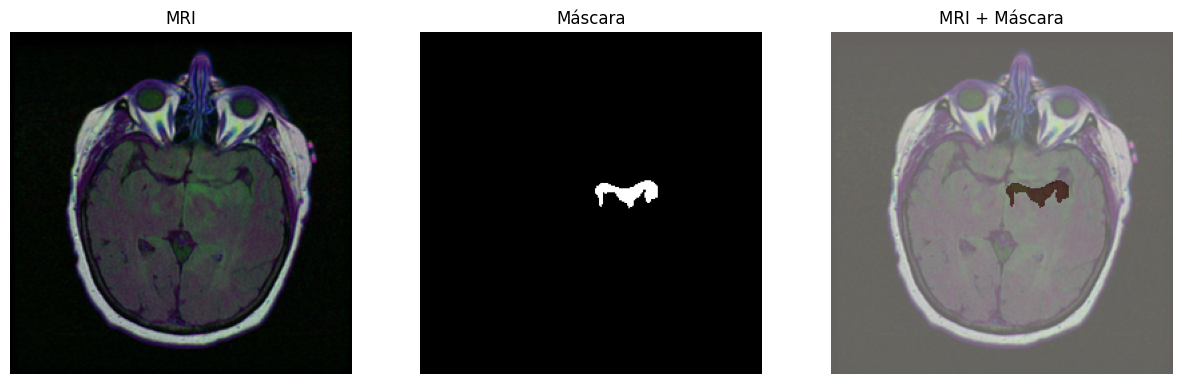

In [11]:
import matplotlib.pyplot as plt


positive_example = df[df["has_tumor"]].iloc[0]

image = np.array(
    Image.open(positive_example["image_path"])
)

mask = np.array(
    Image.open(positive_example["mask_path"])
)


plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Máscara")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.4)
plt.title("MRI + Máscara")
plt.axis("off")

plt.show()

# 5. Divisão do dataset por paciente

O dataset foi dividido em treino, validação e teste por paciente, evitando que imagens do mesmo paciente apareçam em conjuntos diferentes. Essa estratégia reduz o risco de data leakage e torna a avaliação do modelo mais confiável.

In [12]:
patient_summary = (
    df.groupby("patient_id")
    .agg(
        n_images=("image_path", "count"),
        n_positive=("has_tumor", "sum")
    )
    .reset_index()
)

patient_summary["positive_ratio"] = (
    patient_summary["n_positive"] / patient_summary["n_images"]
)

print(patient_summary.head())
print("\nQuantidade de pacientes:", len(patient_summary))

              patient_id  n_images  n_positive  positive_ratio
0  TCGA_CS_4941_19960909        23           8        0.347826
1  TCGA_CS_4942_19970222        20           6        0.300000
2  TCGA_CS_4943_20000902        20           8        0.400000
3  TCGA_CS_4944_20010208        20           9        0.450000
4  TCGA_CS_5393_19990606        20           8        0.400000

Quantidade de pacientes: 110


In [13]:
from sklearn.model_selection import train_test_split

SEED = 42

patient_ids = patient_summary["patient_id"].tolist()

train_patients, temp_patients = train_test_split(
    patient_ids,
    test_size=0.30,
    random_state=SEED
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=SEED
)

print("Pacientes treino:", len(train_patients))
print("Pacientes validação:", len(val_patients))
print("Pacientes teste:", len(test_patients))

Pacientes treino: 77
Pacientes validação: 16
Pacientes teste: 17


In [14]:
def get_split(patient_id):
    if patient_id in train_patients:
        return "train"
    elif patient_id in val_patients:
        return "val"
    else:
        return "test"


df["split"] = df["patient_id"].apply(get_split)

print(df["split"].value_counts())

split
train    2750
val       618
test      561
Name: count, dtype: int64


Validação de sobreposição entre os conjuntos para confirmar a ausência de data leakage.

In [15]:
train_set = set(train_patients)
val_set = set(val_patients)
test_set = set(test_patients)

print("Treino ∩ Validação:", len(train_set & val_set))
print("Treino ∩ Teste:", len(train_set & test_set))
print("Validação ∩ Teste:", len(val_set & test_set))

Treino ∩ Validação: 0
Treino ∩ Teste: 0
Validação ∩ Teste: 0


In [16]:
split_summary = (
    df.groupby("split")
    .agg(
        imagens=("image_path", "count"),
        com_tumor=("has_tumor", "sum")
    )
)

split_summary["sem_tumor"] = (
    split_summary["imagens"] - split_summary["com_tumor"]
)

split_summary["percentual_tumor"] = (
    split_summary["com_tumor"]
    / split_summary["imagens"]
    * 100
).round(2)

print(split_summary)

       imagens  com_tumor  sem_tumor  percentual_tumor
split                                                 
test       561        224        337             39.93
train     2750        915       1835             33.27
val        618        234        384             37.86


# 6. Preparação do pipeline de dados

In [17]:
!pip install -q albumentations

## 6.1 Transformações, Data Augmentation e normalização

As transformações com Data Augmentation e normalização são utilizadas nos Experimentos 2 e 3. O baseline do Experimento 1 utiliza apenas a transformação mínima necessária para converter os dados para tensores.

In [18]:
import albumentations as A
from albumentations.pytorch import ToTensorV2


train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])


val_test_transform = A.Compose([
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

### 6.1.1 Exemplo visual de Data Augmentation

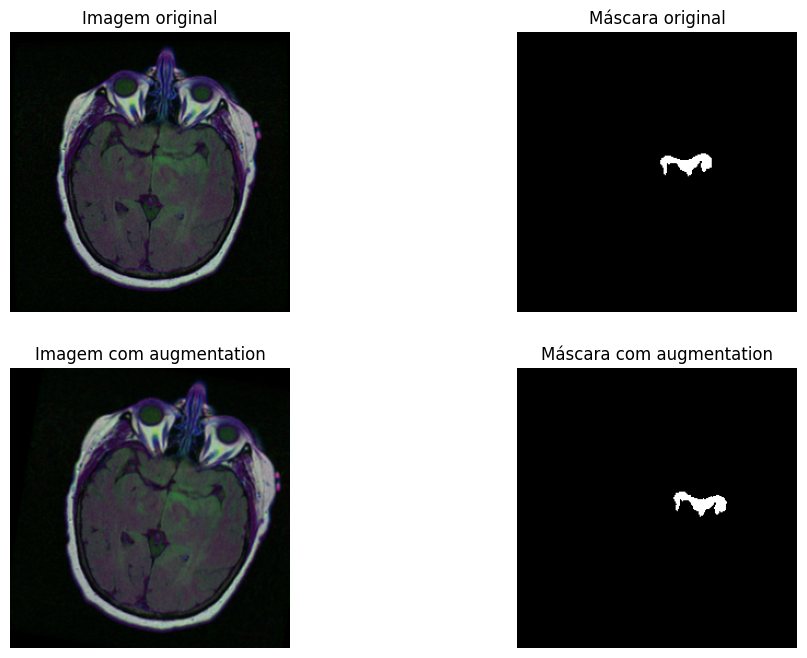

In [19]:
visual_transform = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=1.0
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.5
    )
])


example = df[
    (df["split"] == "train") &
    (df["has_tumor"])
].iloc[0]

image = np.array(Image.open(example["image_path"]))
mask = np.array(Image.open(example["mask_path"]))

augmented = visual_transform(
    image=image,
    mask=mask
)

aug_image = augmented["image"]
aug_mask = augmented["mask"]


plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Máscara original")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(aug_image)
plt.title("Imagem com augmentation")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(aug_mask, cmap="gray")
plt.title("Máscara com augmentation")
plt.axis("off")

plt.show()

## 6.2 DataFrames por split

In [20]:
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 2750
Val: 618
Test: 561


## 6.3 Classe Dataset

In [21]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np


class MRISegmentationDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Carrega imagem RGB
        image = np.array(
            Image.open(row["image_path"]).convert("RGB")
        )

        # Carrega máscara em escala de cinza
        mask = np.array(
            Image.open(row["mask_path"]).convert("L")
        )

        # Converte máscara para binária: 0 ou 1
        mask = (mask > 0).astype(np.float32)

        # Aplica transformações
        if self.transform:
            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        # A máscara precisa ter formato:
        # [1, altura, largura]
        if mask.ndim == 2:
            mask = mask.unsqueeze(0)

        return image.float(), mask.float()

## 6.4 Datasets e DataLoaders dos Experimentos 2 e 3

In [22]:
train_dataset = MRISegmentationDataset(
    train_df,
    transform=train_transform
)

val_dataset = MRISegmentationDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = MRISegmentationDataset(
    test_df,
    transform=val_test_transform
)


print("Train dataset:", len(train_dataset))
print("Val dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 2750
Val dataset: 618
Test dataset: 561


In [23]:
from torch.utils.data import DataLoader


BATCH_SIZE = 8


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

## 6.5 Conferência do pipeline de dados

In [24]:
images, masks = next(iter(train_loader))

print("Formato das imagens:", images.shape)
print("Formato das máscaras:", masks.shape)

print("Tipo das imagens:", images.dtype)
print("Tipo das máscaras:", masks.dtype)

print("Valores únicos da máscara:", torch.unique(masks))

Formato das imagens: torch.Size([8, 3, 256, 256])
Formato das máscaras: torch.Size([8, 1, 256, 256])
Tipo das imagens: torch.float32
Tipo das máscaras: torch.float32
Valores únicos da máscara: tensor([0., 1.])


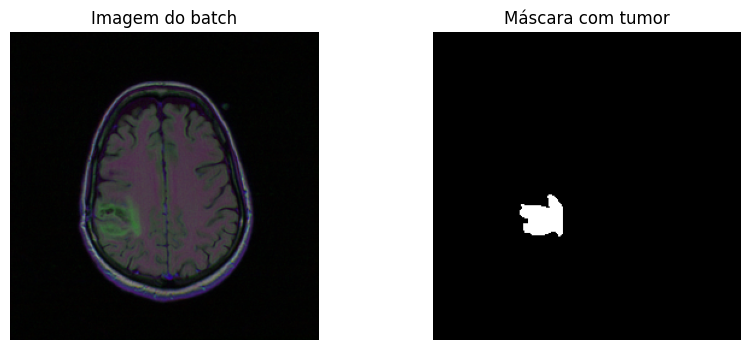

In [25]:
# Procura a primeira máscara positiva do batch
positive_idx = None

for i in range(len(masks)):
    if masks[i].sum() > 0:
        positive_idx = i
        break

if positive_idx is None:
    print("Nenhuma máscara positiva neste batch.")
else:
    image = images[positive_idx]
    mask = masks[positive_idx]

    # Desnormaliza apenas para visualização
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image_vis = image * std + mean
    image_vis = image_vis.permute(1, 2, 0).numpy()
    image_vis = np.clip(image_vis, 0, 1)

    mask_vis = mask.squeeze().numpy()

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image_vis)
    plt.title("Imagem do batch")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask_vis, cmap="gray")
    plt.title("Máscara com tumor")
    plt.axis("off")

    plt.show()

## 6.6 Configuração comum dos experimentos

Para manter a comparação consistente, os experimentos reutilizam a mesma função de perda, métricas e rotinas de treinamento e validação. As diferenças entre os experimentos ficam concentradas no tratamento dos dados e na arquitetura utilizada.

### 6.6.1 Dispositivo de execução

In [26]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda
GPU: Tesla T4


### 6.6.2 Arquitetura U-Net

In [27]:
import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(64, 32)

        # Saída binária
        self.final = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

### 6.6.3 Diretório de resultados e checkpoints

In [28]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brain-MRI-Segmentation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Resultados serão salvos em:")
print(OUTPUT_DIR)

Mounted at /content/drive
Resultados serão salvos em:
/content/drive/MyDrive/Brain-MRI-Segmentation


### 6.6.4 Função de perda

In [29]:
import torch
import torch.nn as nn


bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1e-6):

    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        probabilities * targets
    ).sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1 - dice.mean()


def combined_loss(logits, targets):

    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice

### 6.6.5 Métricas de avaliação

In [30]:
@torch.no_grad()
def calculate_metrics(logits, targets, threshold=0.5):

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        predictions * targets
    ).sum(dim=1)

    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    smooth = 1e-6

    dice = (
        2 * intersection + smooth
    ) / (
        pred_sum + target_sum + smooth
    )

    union = (
        pred_sum
        + target_sum
        - intersection
    )

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    positive_mask = target_sum > 0

    return {
        "dice_all": dice.cpu(),
        "dice_positive": dice[positive_mask].cpu(),
        "iou_positive": iou[positive_mask].cpu()
    }

### 6.6.6 Funções de treinamento e validação

In [31]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    device
):

    model.train()

    total_loss = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [32]:
@torch.no_grad()
def validate(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0

    dice_all_values = []
    dice_positive_values = []
    iou_positive_values = []

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        loss = combined_loss(
            outputs,
            masks
        )

        total_loss += loss.item()

        metrics = calculate_metrics(
            outputs,
            masks
        )

        dice_all_values.extend(
            metrics["dice_all"].tolist()
        )

        dice_positive_values.extend(
            metrics["dice_positive"].tolist()
        )

        iou_positive_values.extend(
            metrics["iou_positive"].tolist()
        )

    return {
        "loss": total_loss / len(loader),

        "dice_all": (
            sum(dice_all_values)
            / len(dice_all_values)
        ),

        "dice_positive": (
            sum(dice_positive_values)
            / len(dice_positive_values)
        ),

        "iou_positive": (
            sum(iou_positive_values)
            / len(iou_positive_values)
        )
    }

# 7. Experimento 1 — Baseline: U-Net com dados crus

O primeiro experimento estabelece o baseline do projeto. Foi utilizada uma U-Net treinada do zero com os dados originais do dataset, sem Data Augmentation e sem normalização baseada no ImageNet. Foi aplicada somente a conversão mínima necessária para disponibilizar imagens e máscaras como tensores para o modelo.

## 7.1 Transformação mínima

In [33]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

baseline_transform = A.Compose([
    A.ToFloat(max_value=255.0),
    ToTensorV2()
])

## 7.2 Datasets do baseline

In [34]:
baseline_train_dataset = MRISegmentationDataset(
    train_df,
    transform=baseline_transform
)

baseline_val_dataset = MRISegmentationDataset(
    val_df,
    transform=baseline_transform
)

baseline_test_dataset = MRISegmentationDataset(
    test_df,
    transform=baseline_transform
)

print("Train:", len(baseline_train_dataset))
print("Val:", len(baseline_val_dataset))
print("Test:", len(baseline_test_dataset))

Train: 2750
Val: 618
Test: 561


## 7.3 DataLoaders do baseline

In [35]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

baseline_train_loader = DataLoader(
    baseline_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

baseline_val_loader = DataLoader(
    baseline_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

baseline_test_loader = DataLoader(
    baseline_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders do baseline criados.")

DataLoaders do baseline criados.


## 7.4 Conferência dos dados

In [36]:
images_baseline, masks_baseline = next(iter(baseline_train_loader))

print("Imagens:", images_baseline.shape)
print("Máscaras:", masks_baseline.shape)

print(
    "Intervalo dos pixels:",
    images_baseline.min().item(),
    "até",
    images_baseline.max().item()
)

print(
    "Valores das máscaras:",
    torch.unique(masks_baseline)
)

Imagens: torch.Size([8, 3, 256, 256])
Máscaras: torch.Size([8, 1, 256, 256])
Intervalo dos pixels: 0.0 até 0.9725490212440491
Valores das máscaras: tensor([0., 1.])


## 7.5 Modelo baseline

In [37]:
model_raw_baseline = UNet().to(device)

print("U-Net baseline com dados crus criada.")

U-Net baseline com dados crus criada.


## 7.6 Configuração do treinamento

In [ ]:
optimizer_raw_baseline = torch.optim.AdamW(
    model_raw_baseline.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler_raw_baseline = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_raw_baseline,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS_RAW_BASELINE = 15

checkpoint_raw_baseline = (
    OUTPUT_DIR / "best_unet_raw_baseline.pth"
)

## 7.7 Treinamento

In [ ]:
history_raw_baseline = []

best_val_loss_raw = float("inf")

early_stop_patience = 5
epochs_without_improvement = 0


for epoch in range(1, EPOCHS_RAW_BASELINE + 1):

    train_loss = train_one_epoch(
        model_raw_baseline,
        baseline_train_loader,
        optimizer_raw_baseline,
        device
    )

    val_metrics = validate(
        model_raw_baseline,
        baseline_val_loader,
        device
    )

    val_loss = val_metrics["loss"]

    scheduler_raw_baseline.step(val_loss)

    current_lr = optimizer_raw_baseline.param_groups[0]["lr"]

    history_raw_baseline.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "dice_all": val_metrics["dice_all"],
        "dice_positive": val_metrics["dice_positive"],
        "iou_positive": val_metrics["iou_positive"],
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS_RAW_BASELINE} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice+: {val_metrics['dice_positive']:.4f} | "
        f"IoU+: {val_metrics['iou_positive']:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss_raw:

        best_val_loss_raw = val_loss

        torch.save(
            model_raw_baseline.state_dict(),
            checkpoint_raw_baseline
        )

        epochs_without_improvement = 0

        print("  -> Melhor baseline salvo")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_patience:
        print("\nEarly stopping: validação não melhorou.")
        break

Epoch 01/15 | Train Loss: 0.5212 | Val Loss: 0.4733 | Dice+: 0.3082 | IoU+: 0.2438 | LR: 0.001000
  -> Melhor baseline salvo
Epoch 02/15 | Train Loss: 0.4359 | Val Loss: 0.4357 | Dice+: 0.4881 | IoU+: 0.3965 | LR: 0.001000
  -> Melhor baseline salvo
Epoch 03/15 | Train Loss: 0.4212 | Val Loss: 0.4212 | Dice+: 0.5543 | IoU+: 0.4574 | LR: 0.001000
  -> Melhor baseline salvo
Epoch 04/15 | Train Loss: 0.4102 | Val Loss: 0.4336 | Dice+: 0.4978 | IoU+: 0.3973 | LR: 0.001000
Epoch 05/15 | Train Loss: 0.4056 | Val Loss: 0.4180 | Dice+: 0.5490 | IoU+: 0.4641 | LR: 0.001000
  -> Melhor baseline salvo
Epoch 06/15 | Train Loss: 0.4013 | Val Loss: 0.4244 | Dice+: 0.5553 | IoU+: 0.4577 | LR: 0.001000
Epoch 07/15 | Train Loss: 0.3988 | Val Loss: 0.4153 | Dice+: 0.5710 | IoU+: 0.4778 | LR: 0.001000
  -> Melhor baseline salvo
Epoch 08/15 | Train Loss: 0.3933 | Val Loss: 0.4220 | Dice+: 0.5339 | IoU+: 0.4475 | LR: 0.001000
Epoch 09/15 | Train Loss: 0.3931 | Val Loss: 0.4105 | Dice+: 0.5811 | IoU+: 0.495

## 7.8 Histórico do treinamento

In [ ]:
history_raw_df = pd.DataFrame(history_raw_baseline)

history_raw_df.to_csv(
    OUTPUT_DIR / "raw_baseline_training_history.csv",
    index=False
)

history_raw_df

,epoch,train_loss,val_loss,dice_all,dice_positive,iou_positive,learning_rate
0,1,0.521197,0.473293,0.657145,0.308187,0.243772,0.0010
1,2,0.435889,0.435719,0.566694,0.488106,0.396475,0.0010
2,3,0.421230,0.421235,0.459061,0.554273,0.457381,0.0010
3,4,0.410211,0.433623,0.448992,0.497765,0.397251,0.0010
4,5,0.405607,0.417966,0.639902,0.548971,0.464107,0.0010
5,6,0.401273,0.424425,0.451362,0.555307,0.457690,0.0010
6,7,0.398826,0.415325,0.510694,0.570978,0.477849,0.0010
7,8,0.393284,0.422046,0.711873,0.533922,0.447525,0.0010
8,9,0.393142,0.410529,0.645601,0.581118,0.495243,0.0010
9,10,0.388010,0.409799,0.721467,0.584901,0.498623,0.0010


## 7.9 Avaliação no conjunto de teste

In [ ]:
model_raw_baseline.load_state_dict(
    torch.load(
        OUTPUT_DIR / "best_unet_raw_baseline.pth",
        map_location=device
    )
)

model_raw_baseline.to(device)
model_raw_baseline.eval()

print("Melhor baseline cru carregado.")

Melhor baseline cru carregado.


In [ ]:
raw_baseline_test = validate(
    model_raw_baseline,
    baseline_test_loader,
    device
)

print("Test Loss:", raw_baseline_test["loss"])
print("Dice:", raw_baseline_test["dice_positive"])
print("IoU:", raw_baseline_test["iou_positive"])

Test Loss: 0.39161453322625495
Dice: 0.6632620856357864
IoU: 0.5569503470397464


# 8. Experimento 2 — U-Net com Data Augmentation e Normalização

No segundo experimento foi mantida a arquitetura U-Net simples utilizada no baseline, porém foram adicionadas técnicas de Data Augmentation e normalização às imagens de treinamento. O objetivo deste experimento é avaliar se essas modificações no pipeline de dados proporcionam melhora no desempenho em relação ao baseline treinado com os dados crus.

## 8.1 Criação e summary do modelo

In [38]:
model_augmented = UNet().to(device)

print("U-Net do Experimento 2 criada com sucesso.")

U-Net do Experimento 2 criada com sucesso.


In [ ]:
!pip install -q torchinfo

In [ ]:
from torchinfo import summary

model_summary = summary(
    model_augmented,
    input_size=(1, 3, 256, 256),
    device=str(device)
)

print(model_summary)

In [ ]:
summary_path = OUTPUT_DIR / "unet_aug_norm_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write(str(model_summary))

print("Summary salvo em:", summary_path)

## 8.2 Validação do formato da saída

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model_augmented(images)

print("Entrada:", images.shape)
print("Saída do modelo:", outputs.shape)
print("Máscara esperada:", masks.shape)

Neste experimento, a U-Net foi treinada utilizando uma combinação de BCEWithLogitsLoss e Dice Loss. A BCE avalia a classificação de cada pixel, enquanto a Dice Loss auxilia no tratamento do desbalanceamento entre a região tumoral e o fundo. O otimizador utilizado foi o AdamW e o desempenho foi acompanhado no conjunto de validação a cada época.

## 8.3 Configuração do treinamento

In [ ]:
optimizer_augmented = torch.optim.AdamW(
    model_augmented.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler_augmented = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_augmented,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS_AUGMENTED = 15
checkpoint_augmented = OUTPUT_DIR / "best_unet_aug_norm.pth"

## 8.4 Treinamento

In [ ]:
history_augmented = []

best_val_loss_augmented = float("inf")

early_stop_patience = 5
epochs_without_improvement = 0


for epoch in range(1, EPOCHS_AUGMENTED + 1):

    train_loss = train_one_epoch(
        model_augmented,
        train_loader,
        optimizer_augmented,
        device
    )

    val_metrics = validate(
        model_augmented,
        val_loader,
        device
    )

    val_loss = val_metrics["loss"]

    scheduler_augmented.step(val_loss)

    current_lr = optimizer_augmented.param_groups[0]["lr"]

    history_augmented.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "dice_all": val_metrics["dice_all"],
        "dice_positive": val_metrics["dice_positive"],
        "iou_positive": val_metrics["iou_positive"],
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS_AUGMENTED} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice+: {val_metrics['dice_positive']:.4f} | "
        f"IoU+: {val_metrics['iou_positive']:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # Salva o melhor checkpoint
    if val_loss < best_val_loss_augmented:

        best_val_loss_augmented = val_loss

        torch.save(
            model_augmented.state_dict(),
            checkpoint_augmented
        )

        epochs_without_improvement = 0

        print("  -> Melhor modelo do Experimento 2 salvo")

    else:

        epochs_without_improvement += 1

    # Early stopping
    if (
        epochs_without_improvement
        >= early_stop_patience
    ):
        print(
            "\nEarly stopping: "
            "validação não melhorou."
        )
        break

Epoch 01/15 | Train Loss: 0.5532 | Val Loss: 0.4529 | Dice+: 0.4687 | IoU+: 0.3732 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 02/15 | Train Loss: 0.4380 | Val Loss: 0.4324 | Dice+: 0.5262 | IoU+: 0.4251 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 03/15 | Train Loss: 0.4207 | Val Loss: 0.4183 | Dice+: 0.5478 | IoU+: 0.4496 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 04/15 | Train Loss: 0.4138 | Val Loss: 0.4285 | Dice+: 0.5002 | IoU+: 0.4120 | LR: 0.001000
Epoch 05/15 | Train Loss: 0.4073 | Val Loss: 0.4209 | Dice+: 0.5573 | IoU+: 0.4523 | LR: 0.001000
Epoch 06/15 | Train Loss: 0.4071 | Val Loss: 0.4122 | Dice+: 0.5798 | IoU+: 0.4841 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 07/15 | Train Loss: 0.4009 | Val Loss: 0.4057 | Dice+: 0.6073 | IoU+: 0.5071 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 08/15 | Train Loss: 0.3990 | Val Loss: 0.4043 | Dice+: 0.5973 | IoU+: 0.5020 | LR: 0.001000
  -> Melhor modelo salvo
Epoch 09/15 | Train Loss: 0.3955 | Val Loss: 0.4054 | Dice+: 0.594

## 8.5 Histórico do treinamento

In [ ]:
import pandas as pd

history_augmented_df = pd.DataFrame(history_augmented)
history_augmented_path = OUTPUT_DIR / "unet_aug_norm_training_history.csv"
history_augmented_df.to_csv(history_augmented_path, index=False)
history_augmented_df

## 8.6 Curvas de aprendizagem

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.plot(
    history_augmented_df["epoch"],
    history_augmented_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_augmented_df["epoch"],
    history_augmented_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("U-Net com Augmentation e Normalização - Loss")
plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_augmented_df["epoch"],
    history_augmented_df["dice_positive"],
    label="Dice"
)

plt.plot(
    history_augmented_df["epoch"],
    history_augmented_df["iou_positive"],
    label="IoU"
)

plt.xlabel("Época")
plt.ylabel("Métrica")
plt.title(
    "U-Net com Augmentation e Normalização - Validação com tumor"
)

plt.legend()

plt.show()

# 9. Experimento 3 — U-Net com ResNet34 e Transfer Learning

No terceiro experimento foi utilizada uma U-Net com encoder ResNet34 pré-treinado no ImageNet. Diferente da U-Net simples utilizada nos experimentos anteriores, este modelo parte de características visuais previamente aprendidas em um grande conjunto de imagens. O objetivo é avaliar se o uso de transfer learning melhora o desempenho da segmentação.

## 9.1 Instalação da biblioteca

In [39]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.8 MB/s eta 0:00:00


In [41]:
import segmentation_models_pytorch as smp

## 9.2 Criação do modelo

In [42]:
model_resnet34 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

print("U-Net com ResNet34 criada com sucesso.")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net com ResNet34 criada com sucesso.


## 9.3 Summary do modelo

In [ ]:
from torchinfo import summary

resnet34_summary = summary(
    model_resnet34,
    input_size=(1, 3, 256, 256),
    device=str(device)
)

print(resnet34_summary)

Layer (type:depth-idx)                        Output Shape              Param #
Unet                                          [1, 1, 256, 256]          --
├─ResNetEncoder: 1-1                          [1, 3, 256, 256]          --
│    └─Conv2d: 2-1                            [1, 64, 128, 128]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 128, 128]         128
│    └─ReLU: 2-3                              [1, 64, 128, 128]         --
│    └─MaxPool2d: 2-4                         [1, 64, 64, 64]           --
│    └─Sequential: 2-5                        [1, 64, 64, 64]           --
│    │    └─BasicBlock: 3-1                   [1, 64, 64, 64]           73,984
│    │    └─BasicBlock: 3-2                   [1, 64, 64, 64]           73,984
│    │    └─BasicBlock: 3-3                   [1, 64, 64, 64]           73,984
│    └─Sequential: 2-6                        [1, 128, 32, 32]          --
│    │    └─BasicBlock: 3-4                   [1, 128, 32, 32]          230,144

In [ ]:
summary_path_resnet = (
    OUTPUT_DIR / "unet_resnet34_summary.txt"
)

with open(
    summary_path_resnet,
    "w",
    encoding="utf-8"
) as f:
    f.write(str(resnet34_summary))

print("Summary salvo em:", summary_path_resnet)

Summary salvo em: /content/drive/MyDrive/Brain-MRI-Segmentation/unet_resnet34_summary.txt


## 9.4 Validação do formato da saída

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model_resnet34(images)

print("Entrada:", images.shape)
print("Saída:", outputs.shape)
print("Máscara:", masks.shape)

Entrada: torch.Size([8, 3, 256, 256])
Saída: torch.Size([8, 1, 256, 256])
Máscara: torch.Size([8, 1, 256, 256])


## 9.5 Configuração do treinamento

Como o encoder utiliza pesos pré-treinados no ImageNet, foi adotada uma learning rate menor para o fine-tuning.

In [ ]:
optimizer_resnet = torch.optim.AdamW(
    model_resnet34.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_resnet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS_RESNET = 15

checkpoint_resnet = (
    OUTPUT_DIR
    / "best_unet_resnet34.pth"
)

## 9.6 Treinamento

In [ ]:
history_resnet = []

best_val_loss_resnet = float("inf")

early_stop_patience = 5
epochs_without_improvement = 0


for epoch in range(1, EPOCHS_RESNET + 1):

    train_loss = train_one_epoch(
        model_resnet34,
        train_loader,
        optimizer_resnet,
        device
    )

    val_metrics = validate(
        model_resnet34,
        val_loader,
        device
    )

    val_loss = val_metrics["loss"]

    scheduler_resnet.step(val_loss)

    current_lr = (
        optimizer_resnet
        .param_groups[0]["lr"]
    )

    history_resnet.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "dice_all": val_metrics["dice_all"],
        "dice_positive": val_metrics["dice_positive"],
        "iou_positive": val_metrics["iou_positive"],
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS_RESNET} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice+: {val_metrics['dice_positive']:.4f} | "
        f"IoU+: {val_metrics['iou_positive']:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss_resnet:

        best_val_loss_resnet = val_loss

        torch.save(
            model_resnet34.state_dict(),
            checkpoint_resnet
        )

        epochs_without_improvement = 0

        print("  -> Melhor modelo salvo")

    else:
        epochs_without_improvement += 1

    if (
        epochs_without_improvement
        >= early_stop_patience
    ):
        print(
            "\nEarly stopping: "
            "validação não melhorou."
        )
        break

Epoch 01/15 | Train Loss: 0.6196 | Val Loss: 0.5054 | Dice+: 0.5887 | IoU+: 0.5060 | LR: 0.000100
  -> Melhor modelo salvo
Epoch 02/15 | Train Loss: 0.4644 | Val Loss: 0.4231 | Dice+: 0.7046 | IoU+: 0.5946 | LR: 0.000100
  -> Melhor modelo salvo
Epoch 03/15 | Train Loss: 0.4134 | Val Loss: 0.3933 | Dice+: 0.7141 | IoU+: 0.6250 | LR: 0.000100
  -> Melhor modelo salvo
Epoch 04/15 | Train Loss: 0.3921 | Val Loss: 0.3746 | Dice+: 0.7477 | IoU+: 0.6484 | LR: 0.000100
  -> Melhor modelo salvo
Epoch 05/15 | Train Loss: 0.3819 | Val Loss: 0.3581 | Dice+: 0.8139 | IoU+: 0.7224 | LR: 0.000100
  -> Melhor modelo salvo
Epoch 06/15 | Train Loss: 0.3753 | Val Loss: 0.3663 | Dice+: 0.7618 | IoU+: 0.6744 | LR: 0.000100
Epoch 07/15 | Train Loss: 0.3728 | Val Loss: 0.3606 | Dice+: 0.7851 | IoU+: 0.6965 | LR: 0.000100
Epoch 08/15 | Train Loss: 0.3741 | Val Loss: 0.3582 | Dice+: 0.8028 | IoU+: 0.7064 | LR: 0.000050
Epoch 09/15 | Train Loss: 0.3672 | Val Loss: 0.3556 | Dice+: 0.8038 | IoU+: 0.7141 | LR: 0.

## 9.7 Histórico do treinamento

In [ ]:
history_resnet_df = pd.DataFrame(
    history_resnet
)

history_resnet_path = (
    OUTPUT_DIR
    / "resnet34_training_history.csv"
)

history_resnet_df.to_csv(
    history_resnet_path,
    index=False
)

history_resnet_df

,epoch,train_loss,val_loss,dice_all,dice_positive,iou_positive,learning_rate
0,1,0.619565,0.505424,0.672754,0.588727,0.505993,0.000100
1,2,0.464392,0.423141,0.629255,0.704615,0.594615,0.000100
2,3,0.413413,0.393294,0.739657,0.714136,0.624988,0.000100
3,4,0.392089,0.374557,0.859178,0.747744,0.648408,0.000100
4,5,0.381889,0.358123,0.790378,0.813905,0.722435,0.000100
5,6,0.375276,0.366252,0.874208,0.761796,0.674350,0.000100
6,7,0.372840,0.360556,0.849058,0.785120,0.696548,0.000100
7,8,0.374135,0.358244,0.524056,0.802850,0.706439,0.000050
8,9,0.367180,0.355613,0.757412,0.803762,0.714126,0.000050
9,10,0.365860,0.351745,0.744812,0.821768,0.731848,0.000050


## 9.8 Curvas de aprendizagem

### Curva de Loss

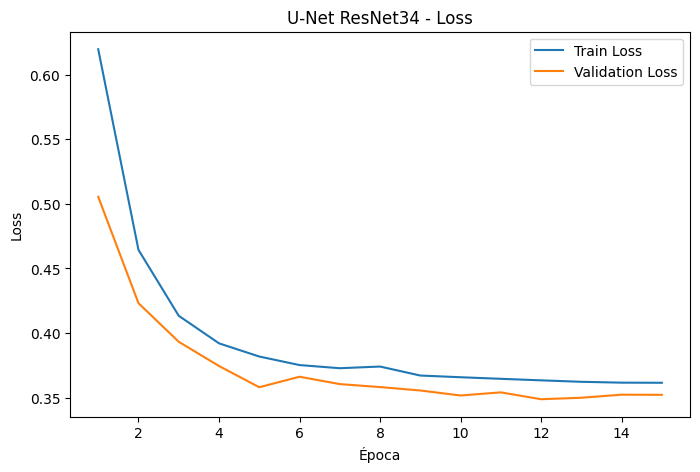

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_resnet_df["epoch"],
    history_resnet_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_resnet_df["epoch"],
    history_resnet_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("U-Net ResNet34 - Loss")
plt.legend()

plt.show()

### Dice e IoU

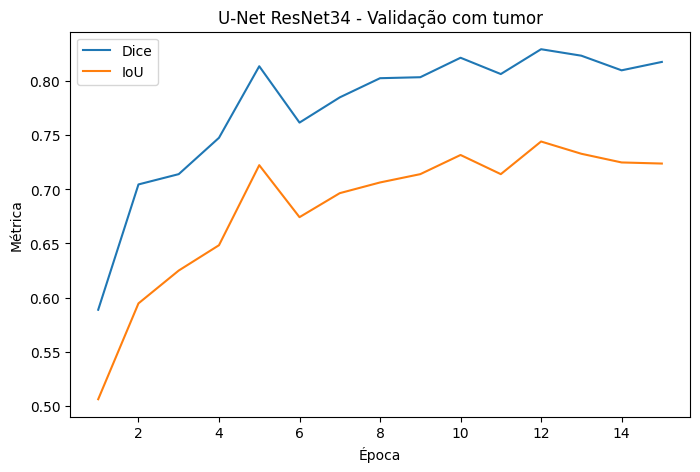

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_resnet_df["epoch"],
    history_resnet_df["dice_positive"],
    label="Dice"
)

plt.plot(
    history_resnet_df["epoch"],
    history_resnet_df["iou_positive"],
    label="IoU"
)

plt.xlabel("Época")
plt.ylabel("Métrica")

plt.title(
    "U-Net ResNet34 - Validação com tumor"
)

plt.legend()

plt.show()

# 10. Avaliação final no conjunto de teste

Cada modelo é avaliado com o mesmo conjunto de pacientes de teste. O baseline utiliza o `baseline_test_loader`, com a transformação mínima, enquanto os Experimentos 2 e 3 utilizam o `test_loader`, que aplica a normalização definida no pipeline desses modelos.

In [43]:
# Experimento 1 — baseline com dados crus
model_raw_baseline.load_state_dict(
    torch.load(OUTPUT_DIR / "best_unet_raw_baseline.pth", map_location=device)
)
model_raw_baseline.to(device).eval()

# Experimento 2 — U-Net com augmentation + normalização
checkpoint_augmented_load = OUTPUT_DIR / "best_unet_aug_norm.pth"
legacy_checkpoint = OUTPUT_DIR / "best_unet_baseline.pth"
if not checkpoint_augmented_load.exists() and legacy_checkpoint.exists():
    checkpoint_augmented_load = legacy_checkpoint

model_augmented.load_state_dict(
    torch.load(checkpoint_augmented_load, map_location=device)
)
model_augmented.to(device).eval()

# Experimento 3 — U-Net + ResNet34
model_resnet34.load_state_dict(
    torch.load(OUTPUT_DIR / "best_unet_resnet34.pth", map_location=device)
)
model_resnet34.to(device).eval()

print("Melhores checkpoints dos três experimentos carregados.")

Melhores checkpoints dos três experimentos carregados.


In [44]:
raw_baseline_test = validate(model_raw_baseline, baseline_test_loader, device)
augmented_test = validate(model_augmented, test_loader, device)
resnet_test = validate(model_resnet34, test_loader, device)

In [45]:
results = pd.DataFrame([
    {"Experimento": "1 - U-Net com dados crus", "Test Loss": raw_baseline_test["loss"], "Dice": raw_baseline_test["dice_positive"], "IoU": raw_baseline_test["iou_positive"]},
    {"Experimento": "2 - U-Net + Aug/Norm", "Test Loss": augmented_test["loss"], "Dice": augmented_test["dice_positive"], "IoU": augmented_test["iou_positive"]},
    {"Experimento": "3 - U-Net + ResNet34", "Test Loss": resnet_test["loss"], "Dice": resnet_test["dice_positive"], "IoU": resnet_test["iou_positive"]}
])
results

,Experimento,Test Loss,Dice,IoU
0,1 - U-Net com dados crus,0.391615,0.663262,0.556950
1,2 - U-Net + Aug/Norm,0.409019,0.630268,0.527259
2,3 - U-Net + ResNet34,0.359049,0.790816,0.699230


In [46]:
results.to_csv(OUTPUT_DIR / "experiment_comparison.csv", index=False)

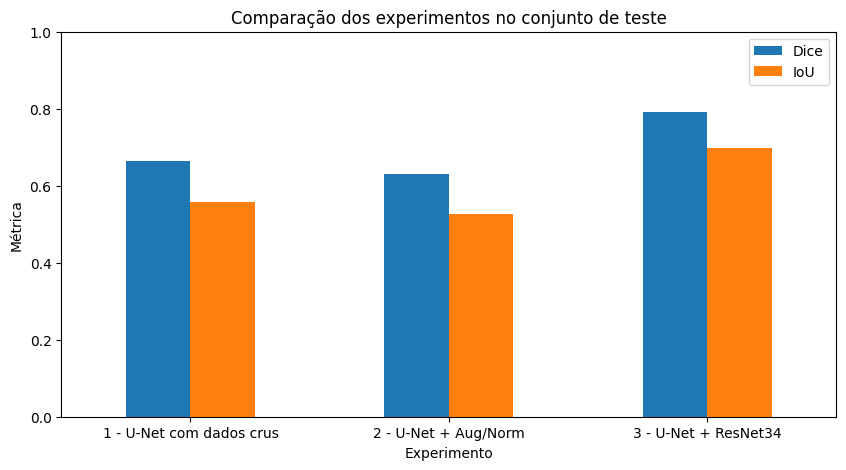

In [47]:
results.set_index("Experimento")[["Dice", "IoU"]].plot(kind="bar", figsize=(10, 5))
plt.title("Comparação dos experimentos no conjunto de teste")
plt.ylabel("Métrica")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

# 11. Comparação dos experimentos

Os resultados no conjunto de teste mostram diferenças importantes entre os três experimentos. O baseline com dados crus alcançou **Dice de 0,6633** e **IoU de 0,5570**. A U-Net com Data Augmentation e normalização obteve **Dice de 0,6303** e **IoU de 0,5273**, não superando o baseline neste conjunto de teste. Já a U-Net com encoder ResNet34 apresentou o melhor desempenho, com **Dice de 0,7908** e **IoU de 0,6992**.

O resultado do Experimento 2 mostra que as transformações utilizadas não produziram ganho sobre o baseline, reforçando a importância de medir cada alteração em vez de assumir que Data Augmentation necessariamente melhora o modelo. O Experimento 3, que manteve o pipeline normalizado e alterou a arquitetura para uma U-Net com encoder ResNet34 pré-treinado, apresentou o melhor desempenho geral.

# 12. Visualização qualitativa das predições

In [48]:
@torch.no_grad()
def predict_mask(model, image, threshold=0.5):
    model.eval()

    logits = model(image.unsqueeze(0).to(device))
    probability = torch.sigmoid(logits)

    prediction = (probability >= threshold).float()

    return prediction.squeeze().cpu().numpy()

In [49]:
positive_test_indices = [
    i
    for i in range(len(test_dataset))
    if test_df.iloc[i]["has_tumor"]
]

print("Imagens positivas no teste:", len(positive_test_indices))

Imagens positivas no teste: 224


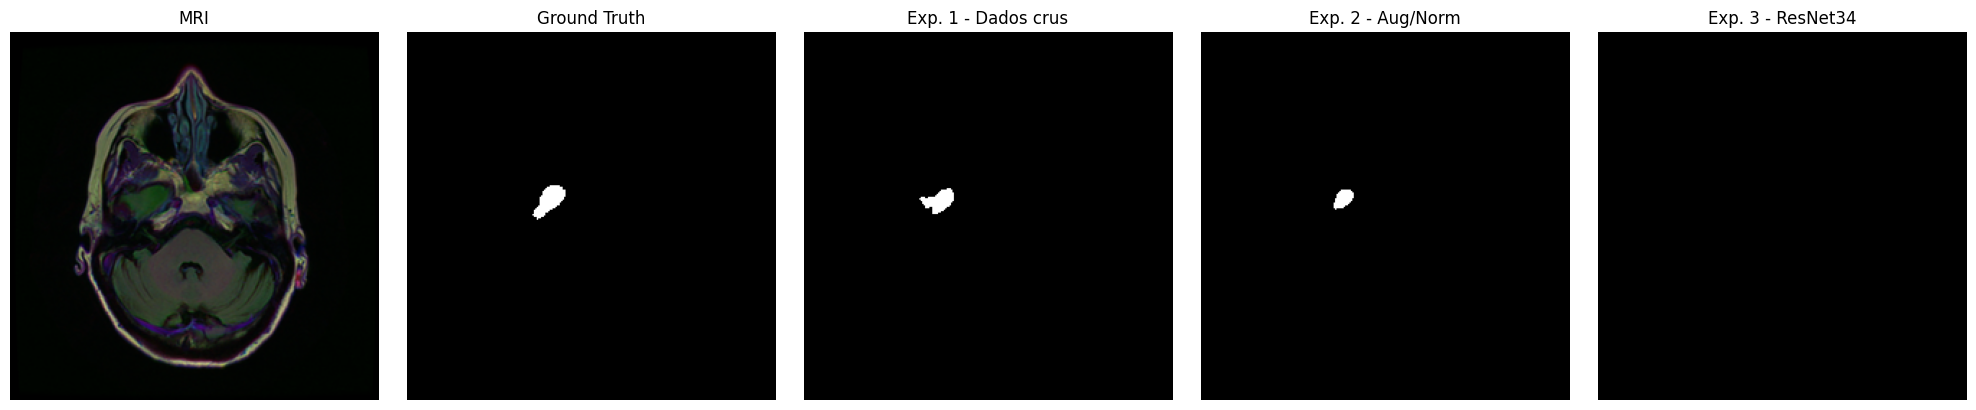

In [50]:
index = positive_test_indices[0]
raw_image, raw_mask = baseline_test_dataset[index]
processed_image, _ = test_dataset[index]

raw_pred = predict_mask(model_raw_baseline, raw_image)
augmented_pred = predict_mask(model_augmented, processed_image)
resnet_pred = predict_mask(model_resnet34, processed_image)

image_vis = raw_image.permute(1, 2, 0).numpy()
image_vis = np.clip(image_vis, 0, 1)
mask_vis = raw_mask.squeeze().numpy()

plt.figure(figsize=(20, 4))
for pos, (arr, title) in enumerate([
    (image_vis, "MRI"),
    (mask_vis, "Ground Truth"),
    (raw_pred, "Exp. 1 - Dados crus"),
    (augmented_pred, "Exp. 2 - Aug/Norm"),
    (resnet_pred, "Exp. 3 - ResNet34")
], start=1):
    plt.subplot(1, 5, pos)
    plt.imshow(arr, cmap=None if pos == 1 else "gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# 13. Conclusões

Os experimentos permitiram avaliar progressivamente diferentes estratégias para a segmentação de tumores em imagens de ressonância magnética. O baseline com dados crus forneceu uma referência necessária para medir o impacto das modificações posteriores.

A inclusão de Data Augmentation e normalização no segundo experimento não melhorou o desempenho no conjunto de teste em relação ao baseline, mostrando que essas técnicas precisam ser avaliadas empiricamente para cada problema. O terceiro experimento, utilizando uma U-Net com encoder ResNet34 pré-treinado, apresentou os melhores resultados entre as configurações testadas.

A comparação reforça a importância de manter um baseline simples, utilizar a mesma divisão de pacientes nos experimentos e registrar também alterações que não produziram ganho, pois esses resultados ajudam a identificar quais decisões realmente contribuíram para o desempenho final.